In [33]:
import numpy as np
import matplotlib.pyplot as plt

# list of rules
total_rules = ['111', '110', '101', '100', '011', '010', '001', '000']

In [34]:
# rule translator
def convert_rule_number(number: int):
    str = format(number, f'0{8}b')
    return list(str)
    
# convert_rule_number(150)

def generate_rule_list(rule_number):
    ruled_values = convert_rule_number(rule_number)
    # print(ruled_values)
    assert(len(total_rules) == len(ruled_values))

    # write rules to a dictionary
    rule_dict = {}
    for input, output in zip(total_rules, ruled_values):
        # print(input, output)
        rule_dict[input] = output
    # print(rule_dict)
    return rule_dict

# Rule_dict = generate_rule_list(150)
# print(Rule_dict)

def check_rule_for_position(time, position, matrix):
    out = [0,0,0]
    size = matrix.shape[1]
    out[0] = matrix[time-1, (position-1) % size]
    out[1] = matrix[time-1, position % size]
    out[2] = matrix[time-1, (position+1) % size]
    return f"{out[0]}{out[1]}{out[2]}"

def calculate_value(time, position, matrix, rule_dict):
    rule = check_rule_for_position(time, position, matrix)
    value = int(rule_dict[rule])
    return value

def calculate_value_reverse(time, position, matrix, rule_dict, reverse):
    rule = check_rule_for_position(time, position, matrix)
    value = int(rule_dict[rule])
    if reverse:
        value = (value + matrix[time-2, position]) % 2
    return value



Rules:
{'111': '1', '110': '0', '101': '0', '100': '1', '011': '0', '010': '1', '001': '1', '000': '0'}


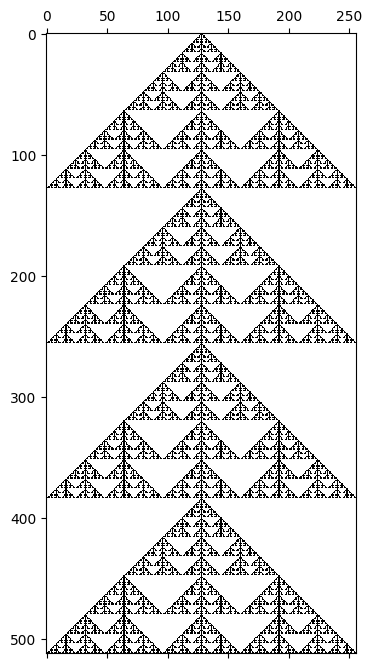

In [35]:
def simulte_cellular_1D(size, start_stop, time_limit, rule_number, reversed=False):
    Matrix = np.zeros((time_limit, size), dtype="int")
    Rule_dict = generate_rule_list(rule_number)
    print(f"Rules:\n{Rule_dict}")
    # first axis is time, second axis is position

    # initialise a state at t = 0
    Matrix[0,start_stop[0]:(start_stop[1]+1)] = 1

    # need to iterate over time
    for time in range(Matrix.shape[0]):
    # for time in [1,2,3,4,5]:
        if time == 0: continue
        # this loop will iterate over all time except 0
        for pos in range(Matrix.shape[1]):
            # compute this for every row
            Matrix[time, pos] = calculate_value_reverse(time, pos, Matrix, Rule_dict, reversed)

    return Matrix

Matrix = simulte_cellular_1D(256, (128,128), 512, 150)
plt.matshow(Matrix, cmap="binary")
# cmap binary is 0 = white, 1 = black

In [36]:
# task 2 - microscopic entropy

# generate the list of binary combinations
from itertools import product

def generate_initial_conditions(size):
    binary_combinations = [''.join(bits) for bits in product('01', repeat=size)]
    return binary_combinations

number_of_bits = 10

initials = generate_initial_conditions(number_of_bits)
print(initials)


['0000000000', '0000000001', '0000000010', '0000000011', '0000000100', '0000000101', '0000000110', '0000000111', '0000001000', '0000001001', '0000001010', '0000001011', '0000001100', '0000001101', '0000001110', '0000001111', '0000010000', '0000010001', '0000010010', '0000010011', '0000010100', '0000010101', '0000010110', '0000010111', '0000011000', '0000011001', '0000011010', '0000011011', '0000011100', '0000011101', '0000011110', '0000011111', '0000100000', '0000100001', '0000100010', '0000100011', '0000100100', '0000100101', '0000100110', '0000100111', '0000101000', '0000101001', '0000101010', '0000101011', '0000101100', '0000101101', '0000101110', '0000101111', '0000110000', '0000110001', '0000110010', '0000110011', '0000110100', '0000110101', '0000110110', '0000110111', '0000111000', '0000111001', '0000111010', '0000111011', '0000111100', '0000111101', '0000111110', '0000111111', '0001000000', '0001000001', '0001000010', '0001000011', '0001000100', '0001000101', '0001000110', '0001

array([[   0,    1,    2, ..., 1021, 1022, 1023],
       [   0,  514,    5, ...,    7,  515,    0],
       [   0,  260,  520, ...,  496,  248, 1023],
       ...,
       [   0,  514,    5, ...,    7,  515,    0],
       [   0,  260,  520, ..., 1021, 1022, 1023],
       [   0,  136,  272, ...,    0,    0,    0]], shape=(256, 1024))

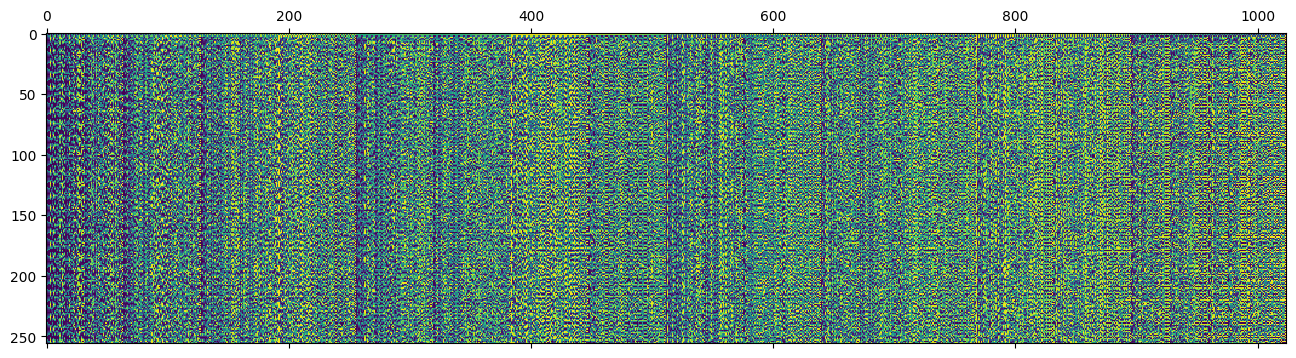

In [41]:
def row_to_decimal(row):
    """Convert a binary row (array of 0/1) to a decimal integer."""
    # row is like [1,0,1,0,1,0,0]
    return int("".join(str(b) for b in row), 2)

def simulte_cellular_1D_initial(initial, time_limit, rule_number, reversed=False):
    size = len(initial)
    row = np.array([int(b) for b in initial])
    # print(row)
    Matrix = np.zeros((time_limit, size), dtype="int")
    Rule_dict = generate_rule_list(rule_number)
    # print(f"Rules:\n{Rule_dict}")
    # first axis is time, second axis is position

    # initialise a state at t = 0
    Matrix[0, :] = row

    # need to iterate over time
    for time in range(Matrix.shape[0]):
        if time == 0: continue # the state at time 0 is already set by the initial condition

        for pos in range(Matrix.shape[1]):
            # compute this for every row
            Matrix[time, pos] = calculate_value_reverse(time, pos, Matrix, Rule_dict, reversed)

    evolution = np.array([row_to_decimal(row) for row in Matrix])
    return evolution

time_limit = 256
rule_number = 122

# pre-allocate the matrix: shape (time, number of initials)
all_evolutions = np.zeros((time_limit, len(initials)), dtype=int)

for idx, init in enumerate(initials):
    evolution = simulte_cellular_1D_initial(init, time_limit, rule_number, reversed=True)
    all_evolutions[:, idx] = evolution  # assign the evolution column-wise

# print(all_evolutions.shape)  # should be (50, len(initials))
plt.matshow(all_evolutions) # time is the y axis, initials is the x axis
all_evolutions

row: 0 
 [   0    1    2 ... 1021 1022 1023]
values:
 [   0    1    2 ... 1021 1022 1023]
counts:
 [1 1 1 ... 1 1 1]
probabilities:
 [0.00097656 0.00097656 0.00097656 ... 0.00097656 0.00097656 0.00097656]
Sum S: 10.0

row: 1 
 [  0 514   5 ...   7 515   0]
values:
 [   0    5    7   10   14   15   20   21   27   28   30   40   42   45
   47   51   54   55   56   59   60   61   63   80   84   85   90   91
   94   95   99  102  107  108  109  110  112  118  119  120  122  125
  126  127  160  165  168  170  173  175  179  180  181  182  187  188
  189  190  195  198  203  204  205  211  214  215  216  218  219  220
  221  223  224  231  235  236  238  239  240  244  245  247  250  251
  252  254  255  257  261  267  271  277  283  287  297  299  301  303
  307  311  317  320  321  325  330  331  335  336  337  340  341  346
  347  350  351  355  358  359  360  361  362  363  364  365  367  371
  374  375  376  377  378  379  380  381  383  387  390  391  395  396
  397  406  407  408  40

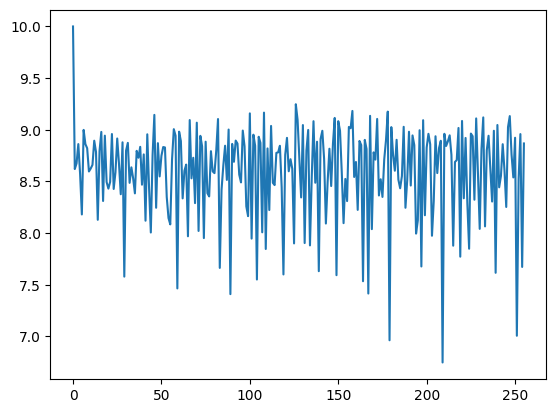

In [42]:
# now calculate the entropy per each row (time step) across all initial conditions

def row_entropy_Gibbs(row):
    values, counts = np.unique(row, return_counts=True)
    prob = counts / counts.sum()
    S = - np.sum(prob * np.log2(prob))

    return S

entropies = np.array([row_entropy_Gibbs(row) for row in all_evolutions])

plt.plot(entropies)
for i, row in enumerate(all_evolutions):
    if i > 5: break
    print("row:",i, "\n", row)
    values, counts = np.unique(row, return_counts=True)
    print("values:\n", values)
    print("counts:\n", counts)
    prob = counts / counts.sum()
    S = - np.sum(prob * np.log2(prob))
    print("probabilities:\n", prob)
    print("Sum S:", S)
    print()